# 2.06. Interleaving тестирование

**План занятия**

1. Почему A/B-тест дорог для сравнения ранжировщиков и в чём идея interleaving.
2. Модель кликов: симулятор, на котором проверяем всё остальное.
3. Как смешивать выдачи: Balanced, Team Draft, competitive pairs.
4. От кликов к решению: победы, Δ, статистический тест и единица анализа.
5. Насколько interleaving чувствительнее A/B-теста.
6. Как проверить, что interleaving работает.
7. Ограничения: чего interleaving не измеряет.
8. Развитие метода и кейсы, в том числе counterfactual interleaving в Авито и LinkedIn.

### Библиотеки

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from ipywidgets import IntSlider, SelectionSlider, interact
from matplotlib.patches import FancyBboxPatch, Patch
from scipy import stats
from scipy.special import expit

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
ALPHA = 0.05

## Почему A/B-тест дорог для сравнения ранжировщиков

Представим поиск, рекомендации или ленту. У команды есть текущий алгоритм ранжирования и новый кандидат. Обе модели показывают почти одни и те же объекты, а отличаются порядком части из них. Эффект на клики или покупки поэтому мал, зато разброс между пользователями огромен: кто-то заходит раз в месяц, кто-то каждый день.

В обычном A/B-тесте эти две величины определяют размер выборки. Всего на две группы нужно примерно

$$N_{AB} \approx \frac{4\,(z_{1-\alpha/2} + z_{1-\beta})^2\,\sigma^2}{\delta^2},$$

где $\sigma^2$ — дисперсия метрики между пользователями, а $\delta$ — эффект. Если $\delta$ составляет доли процента, тест занимает недели, а кандидатов у команды могут быть десятки.

**Идея interleaving.** Вместо двух групп пользователей показываем каждому пользователю **одну смешанную выдачу**, собранную из результатов обоих ранжировщиков, и смотрим, чьи объекты он выбирает. Это парное сравнение: один и тот же человек, в том же запросе, в тот же момент выбирает между A и B. Разница между людьми перестаёт попадать в оценку.

Отсюда и обычная схема работы, которую описывают Airbnb и Amazon: interleaving на малой доле трафика быстро отсеивает кандидатов, а финалист проходит обычный A/B-тест, который уже измеряет бизнес-эффект.

Важно сразу зафиксировать разницу в вопросах:

* **A/B-тест:** как изменится метрика, если всем пользователям включить B?
* **Interleaving:** какой из двух ранжировщиков пользователи предпочитают в прямом сравнении?

Это разные вопросы. Почти всё, что мы обсудим в разделе про ограничения, следует именно из этого.

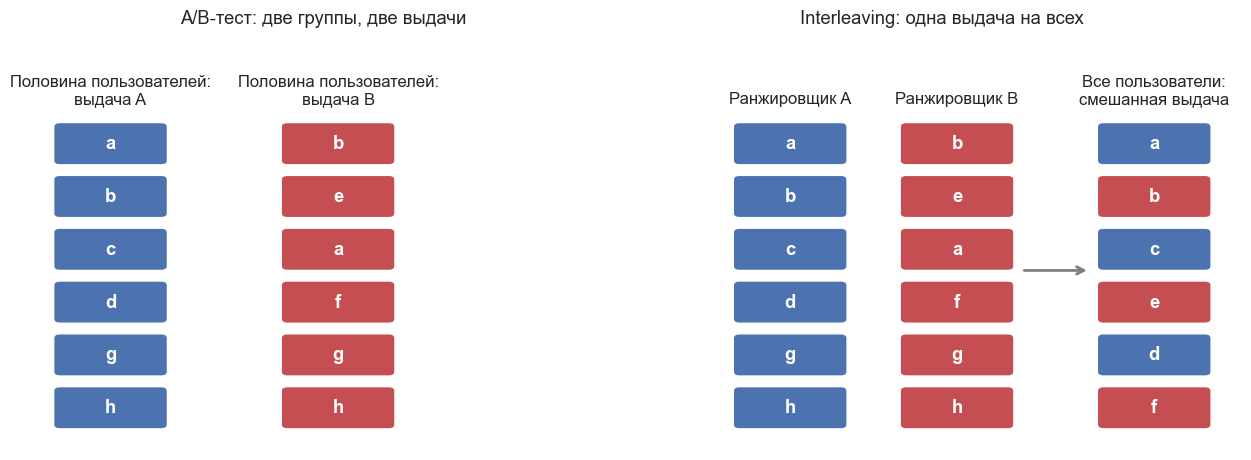

In [2]:
def draw_ranking(ax, x: float, items: list, colors: list, title: str, width: float = 1.5) -> None:
    """Рисует выдачу столбиком сверху вниз."""
    for position, (item, color) in enumerate(zip(items, colors)):
        ax.add_patch(FancyBboxPatch((x, -position), width, 0.8, boxstyle='round,pad=0,rounding_size=0.08', facecolor=color, edgecolor='white'))
        ax.text(x + width / 2, 0.4 - position, item, ha='center', va='center', color='white', fontweight='bold')
    ax.text(x + width / 2, 1.1, title, ha='center', va='bottom', fontsize=12)


ranking_a = list('abcdgh')
ranking_b = list('beafgh')
merged_example = list('abcedf')
merged_colors = [BLUE, RED, BLUE, RED, BLUE, RED]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
draw_ranking(axes[0], 0, ranking_a, [BLUE] * 6, 'Половина пользователей:\nвыдача A')
draw_ranking(axes[0], 3, ranking_b, [RED] * 6, 'Половина пользователей:\nвыдача B')
axes[0].set_title('A/B-тест: две группы, две выдачи', pad=18)
draw_ranking(axes[1], 0.8, ranking_a, [BLUE] * 6, 'Ранжировщик A')
draw_ranking(axes[1], 3.0, ranking_b, [RED] * 6, 'Ранжировщик B')
draw_ranking(axes[1], 5.6, merged_example, merged_colors, 'Все пользователи:\nсмешанная выдача')
axes[1].annotate('', xy=(5.5, -2), xytext=(4.6, -2), arrowprops={'arrowstyle': '->', 'color': GRAY, 'lw': 2})
axes[1].set_title('Interleaving: одна выдача на всех', pad=18)
for ax in axes:
    ax.set(xlim=(-0.4, 7.5), ylim=(-5.4, 2.2))
    ax.axis('off')
plt.tight_layout()
plt.show()

## Модель кликов

Открытых логов с interleaving-экспериментами мы не нашли, поэтому всё проверяем на симуляции, где истинное качество ранжировщиков известно. Выигрыши, которые мы получим, это свойства нашей модели, а не универсальные константы. Зато на ней видно механику: откуда берётся смещение и откуда берётся мощность.

Модель устроена так. У каждого запроса есть 20 документов-кандидатов, пользователь видит 10.

* **Истинная релевантность** документа: $rel_d \sim \mathcal{N}(0, 1)$.
* **Ранжировщики** видят релевантность с шумом. Скор ранжировщика равен $rel_d$ плюс общий шум (из-за него выдачи сильно пересекаются) плюс собственный шум $\sigma_A$ или $\sigma_B$. Чем меньше собственный шум, тем ранжировщик лучше. Дополнительно A слегка поднимает документы типа $x_d = +1$, а B документы типа $x_d = -1$: так ранжировщики различаются, даже когда равны по качеству.
* **Пользователь** $u$ имеет свою склонность кликать $\alpha_u$ и вкус $\theta_u$: одним нравятся документы типа $+1$, другим типа $-1$.
* **Клик** описывает позиционная модель: документ на позиции $r$ получает клик, если пользователь до него дошёл и он ему понравился:

$$P(\text{клик}) = \underbrace{\frac{1}{r}}_{\text{дошёл до позиции}} \cdot \underbrace{\text{logit}^{-1}(\alpha_u + rel_d + \theta_u x_d)}_{\text{понравился}}.$$

Первый множитель и есть **позиционное смещение**: верхние документы кликают чаще просто потому, что они наверху. Из-за него смешивать выдачи надо аккуратно. Это и есть главная задача следующего раздела.

Симулятор сразу считает три сценария для одних и тех же пользователей и запросов: клики при выдаче A, клики при выдаче B и клики при смешанной выдаче. Это потенциальные исходы, в реальности мы видим только один из них.

In [3]:
K, POOL = 10, 20
EXAMINATION = 1 / np.arange(1, K + 1)


def team_draft_batch(A: np.ndarray, B: np.ndarray, rng: np.random.Generator, p_a_first: float = 0.5) -> tuple:
    """Векторная версия Team Draft: возвращает смешанные выдачи и маску документов команды B."""
    n = len(A)
    rows = np.arange(n)
    used = np.zeros((n, POOL), dtype=bool)
    merged = np.empty((n, K), dtype=int)
    from_b = np.zeros((n, K), dtype=bool)
    team_a, team_b = np.zeros(n, dtype=int), np.zeros(n, dtype=int)
    for position in range(K):
        pick_a = (team_a < team_b) | ((team_a == team_b) & (rng.random(n) < p_a_first))
        source = np.where(pick_a[:, None], A, B)
        document = source[rows, (~used[rows[:, None], source]).argmax(axis=1)]
        merged[:, position], from_b[:, position] = document, ~pick_a
        used[rows, document] = True
        team_a, team_b = team_a + pick_a, team_b + ~pick_a
    return merged, from_b


def simulate_pool(n_users: int, sigma_b: float = 1.0, tilt: float = 0.3, taste_sd: float = 0.5, click_sd: float = 1.0,
                  mean_queries: int = 3, p_a_first: float = 0.5, random_clicks: bool = False, seed: int = 0) -> pd.DataFrame:
    """Симулирует пользователей и считает для каждого клики при A, при B и победы в смешанной выдаче."""
    rng = np.random.default_rng(seed)
    n_queries = 1 + rng.poisson(mean_queries - 1, n_users)
    user = np.repeat(np.arange(n_users), n_queries)
    n = len(user)

    alpha = -1.5 + click_sd * rng.normal(size=n_users)
    theta = taste_sd * rng.normal(size=n_users)

    def noise() -> np.ndarray:
        return rng.standard_normal((n, POOL), dtype=np.float32)

    relevance = noise()
    doc_type = 2.0 * rng.integers(0, 2, size=(n, POOL), dtype=np.int8).astype(np.float32) - 1
    shared_noise = 0.5 * noise()
    A = np.argsort(-(relevance + shared_noise + noise() + tilt * doc_type), axis=1)
    B = np.argsort(-(relevance + shared_noise + sigma_b * noise() - tilt * doc_type), axis=1)

    liking = expit(alpha[user, None].astype(np.float32) + relevance + theta[user, None].astype(np.float32) * doc_type)
    if random_clicks:
        liking = np.full_like(liking, 0.3)
    rows = np.arange(n)[:, None]

    # Одни и те же случайные числа для A и B: сравниваем выдачи, а не удачу.
    uniform = rng.random((n, K), dtype=np.float32)
    clicks_a = uniform < EXAMINATION * liking[rows, A[:, :K]]
    clicks_b = uniform < EXAMINATION * liking[rows, B[:, :K]]

    merged, from_b = team_draft_batch(A, B, rng, p_a_first)
    clicks_merged = rng.random((n, K), dtype=np.float32) < EXAMINATION * liking[rows, merged]
    credit_a, credit_b = (clicks_merged & ~from_b).sum(axis=1), (clicks_merged & from_b).sum(axis=1)

    return pd.DataFrame({
        'n_queries': n_queries,
        'clicks_a': np.bincount(user, clicks_a.sum(axis=1), n_users),
        'clicks_b': np.bincount(user, clicks_b.sum(axis=1), n_users),
        'clicks_merged': np.bincount(user, clicks_merged.sum(axis=1), n_users),
        'wins_a': np.bincount(user, credit_a > credit_b, n_users),
        'wins_b': np.bincount(user, credit_b > credit_a, n_users),
        'first_a': np.bincount(user, ~from_b[:, 0], n_users),
    })


pool = simulate_pool(200_000, sigma_b=0.8)
pool[['n_queries', 'clicks_a', 'clicks_b', 'wins_a', 'wins_b']].describe().loc[['mean', 'std']].round(3)

,n_queries,clicks_a,clicks_b,wins_a,wins_b
mean,3.002,3.295,3.396,0.779,0.838
std,1.415,2.751,2.802,0.866,0.895


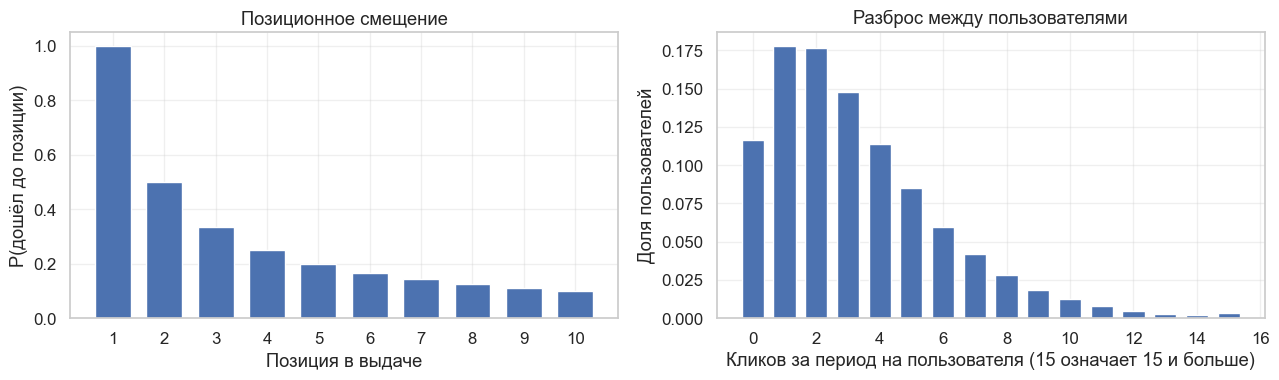

Истинный рост кликов при переходе на B: +3.07%
Стандартное отклонение кликов между пользователями: 2.75 при среднем 3.29


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(np.arange(1, K + 1), EXAMINATION, color=BLUE, width=0.7)
axes[0].set(xlabel='Позиция в выдаче', ylabel='P(дошёл до позиции)', title='Позиционное смещение', xticks=np.arange(1, K + 1))
counts = pool['clicks_a'].clip(upper=15).value_counts(normalize=True).sort_index()
axes[1].bar(counts.index, counts.values, color=BLUE, width=0.7)
axes[1].set(xlabel='Кликов за период на пользователя (15 означает 15 и больше)', ylabel='Доля пользователей', title='Разброс между пользователями')
plt.tight_layout()
plt.show()

lift = pool['clicks_b'].mean() / pool['clicks_a'].mean() - 1
print(f"Истинный рост кликов при переходе на B: {lift:+.2%}")
print(f"Стандартное отклонение кликов между пользователями: {pool['clicks_a'].std():.2f} при среднем {pool['clicks_a'].mean():.2f}")

Рост кликов от B составляет 3.1%, то есть 0.10 клика на пользователя, а стандартное отклонение кликов равно 2.75. Шум примерно в 27 раз больше эффекта. В зрелых продуктах эффекты обычно ещё меньше, поэтому A/B-тесту здесь приходится трудно.

## Как смешивать выдачи

Смешивание должно быть **честным**: если пользователь кликает случайно, ни один ранжировщик не должен получать преимущества. Это условие называют несмещённостью (unbiasedness), Amazon проверяет его как раз на случайно кликающих пользователях.

Наивный способ, например верхняя половина от A и дальше документы от B, этому условию не удовлетворяет: из-за позиционного смещения A выигрывает просто потому, что стоит выше.

**Balanced Interleaving** (Joachims, 2002). Монетка один раз решает, кто начинает, а дальше выдачи чередуются: всегда берём следующий документ из той выдачи, которая отстаёт. Первые $k$ строк смешанной выдачи всегда содержат верхушки обеих выдач, почти равные по размеру. Если документ уже есть в смешанной выдаче, его пропускаем. В исходной версии клики сравниваются по верхушкам обеих выдач, а Amazon в своём примере засчитывает клик ранжировщику, у которого документ стоит выше. Мы берём второй, более простой вариант; смещение есть в обоих.

**Team Draft Interleaving** (Radlinski и др., 2008). Как выбор команд во дворе: два капитана по очереди берут лучшего из оставшихся игроков. В каждом раунде монетка решает, кто выбирает первым, и каждый ранжировщик берёт свой верхний документ, которого ещё нет в смешанной выдаче. Клик засчитывается команде, которая этот документ выбрала.

**Competitive pairs** (Airbnb, 2025). Вариация Team Draft для редких событий вроде бронирований. В каждом ходе берём по следующему доступному документу от обоих ранжировщиков. Если они разные, это соревнующаяся пара, порядок в ней задаёт монетка, брошенная один раз на всю выдачу. Если документ один и тот же, он идёт в выдачу без команды и никому не засчитывается. Победы считаются только внутри пар.

Реализуем все три метода и сверим с примерами из статей.

In [5]:
def balanced_interleave(A: list, B: list, a_first: bool) -> list:
    """Balanced Interleaving: на каждом шаге берём документ из отстающей выдачи."""
    merged, k_a, k_b = [], 0, 0
    while k_a < len(A) or k_b < len(B):
        take_a = k_b >= len(B) or (k_a < len(A) and (k_a < k_b or (k_a == k_b and a_first)))
        if take_a:
            document, k_a = A[k_a], k_a + 1
        else:
            document, k_b = B[k_b], k_b + 1
        if document not in merged:
            merged.append(document)
    return merged


def team_draft(A: list, B: list, coins: list) -> tuple:
    """Team Draft: coins содержит 'A' или 'B', кто выбирает первым в каждом раунде."""
    merged, team_a, team_b = [], [], []
    coins = iter(coins)
    while [d for d in A if d not in merged] and [d for d in B if d not in merged]:
        a_turn = len(team_a) < len(team_b) or (len(team_a) == len(team_b) and next(coins) == 'A')
        source, team = (A, team_a) if a_turn else (B, team_b)
        document = next(d for d in source if d not in merged)
        merged.append(document)
        team.append(document)
    return merged, team_a, team_b


def competitive_pairs(A: list, B: list, a_first: bool) -> tuple:
    """Competitive pairs: разные документы образуют пару, одинаковый идёт в выдачу без команды."""
    merged, pairs = [], []
    length = min(len(A), len(B))
    while len(merged) < length:
        next_a = next((d for d in A if d not in merged), None)
        next_b = next((d for d in B if d not in merged), None)
        if next_a is None or next_b is None:
            break
        if next_a == next_b:
            merged.append(next_a)
        else:
            merged += [next_a, next_b] if a_first else [next_b, next_a]
            pairs.append((next_a, next_b))
    return merged[:length], pairs


# Пример Chapelle et al. (2012), рисунок 1
A, B = list('abcdgh'), list('beafgh')
assert balanced_interleave(A, B, True)[:6] == list('abecdf')
assert balanced_interleave(A, B, False)[:6] == list('baecfd')
assert team_draft(A, B, 'AAAA')[0][:6] == list('abcedf')
assert team_draft(A, B, 'BAAA')[0][:6] == list('bacedf')
assert team_draft(A, B, 'ABAA')[0][:6] == list('abecdf')

# Пример Airbnb (Zhang et al., 2025, раздел 4.1.1)
airbnb_merged, airbnb_pairs = competitive_pairs(list('abcde'), list('bcafg'), True)
assert airbnb_merged == list('abcdf') and airbnb_pairs == [('a', 'b'), ('d', 'f')]
print('Все реализации совпали с примерами из статей')

Все реализации совпали с примерами из статей


Посмотрим, как монетки меняют смешанную выдачу Team Draft. Цвет показывает команду, которая выбрала документ.

In [6]:
def show_team_draft(seed: int = 1) -> None:
    """Рисует смешанную выдачу Team Draft при монетках из заданного зерна."""
    coins = np.random.default_rng(seed).choice(['A', 'B'], size=6).tolist()
    merged, team_a, _ = team_draft(A, B, coins)
    fig, ax = plt.subplots(figsize=(8, 4.6))
    draw_ranking(ax, 0, A, [BLUE] * 6, 'Ранжировщик A')
    draw_ranking(ax, 2.2, B, [RED] * 6, 'Ранжировщик B')
    draw_ranking(ax, 4.8, merged[:6], [BLUE if d in team_a else RED for d in merged[:6]], 'Смешанная выдача')
    ax.annotate('', xy=(4.7, -2), xytext=(3.8, -2), arrowprops={'arrowstyle': '->', 'color': GRAY, 'lw': 2})
    ax.set(xlim=(-0.3, 6.6), ylim=(-5.4, 2), title=f'Первым выбирает в раундах: {", ".join(coins[:3])}')
    ax.axis('off')
    plt.tight_layout()
    plt.show()


interact(show_team_draft, seed=IntSlider(value=1, min=1, max=20, description='Монетки'));

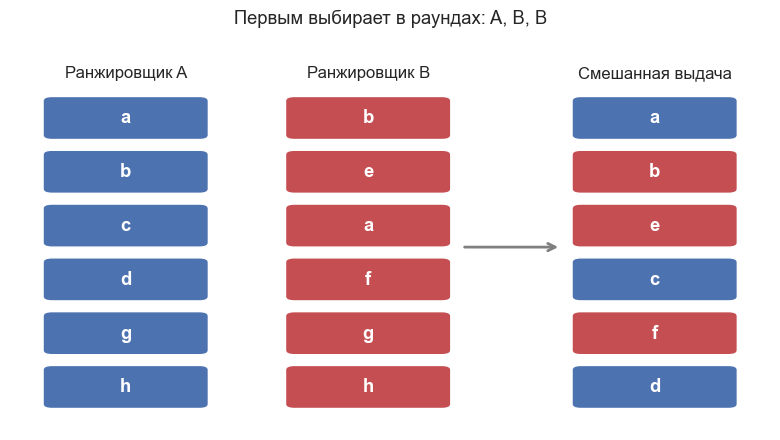

In [7]:
show_team_draft(seed=1)

Теперь проверим несмещённость на примере из статьи Amazon. Выдачи $A = (a_1, a_2, a_3, a_4)$ и $B = (a_1, x, a_2, a_3)$ различаются одним новым документом $x$: B вставил его на вторую позицию и сдвинул остальные вниз. Клики не зависят от документа, то есть у пользователя нет предпочтений. Рассмотрим два варианта: кликает равновероятно на любую позицию (так проверяет Amazon) и кликает сверху вниз с вероятностью $1/r$. Переберём все исходы монеток и посчитаем, какую долю кредита получает A.

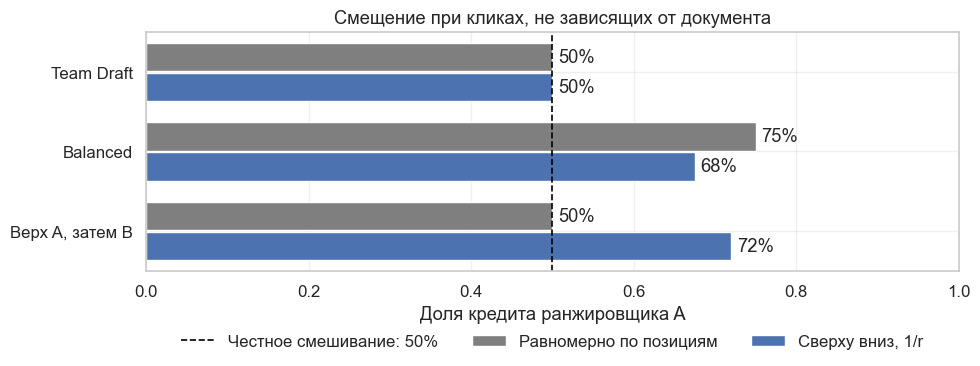

In [8]:
def credit_share_a(merge, credit, click_weight) -> float:
    """Средняя доля кредита A по всем исходам монеток при кликах, не зависящих от документа."""
    points = np.zeros(2)
    for coins in itertools.product('AB', repeat=6):
        merged, owners = merge(coins)
        weights = click_weight(len(merged))
        for document, weight in zip(merged, weights / weights.sum()):
            owner = credit(document, owners)
            if owner:
                points['AB'.index(owner)] += weight
    return points[0] / points.sum()


a_list, b_list = ['a1', 'a2', 'a3', 'a4'], ['a1', 'x', 'a2', 'a3']


def higher_rank_credit(document: str, owners: None) -> str:
    """Кредит ранжировщику, у которого документ стоит выше; при равенстве кредита нет."""
    rank_a = a_list.index(document) if document in a_list else np.inf
    rank_b = b_list.index(document) if document in b_list else np.inf
    return 'A' if rank_a < rank_b else 'B' if rank_b < rank_a else None


def naive_merge(coins):
    merged = a_list[:2] + [d for d in b_list if d not in a_list[:2]]
    return merged, {d: ('A' if d in a_list[:2] else 'B') for d in merged}


def team_merge(coins):
    merged, team_a, team_b = team_draft(a_list, b_list, coins)
    return merged, {d: ('A' if d in team_a else 'B') for d in merged}


click_models = {'Равномерно по позициям': lambda n: np.ones(n), 'Сверху вниз, 1/r': lambda n: 1 / np.arange(1, n + 1)}
owner_credit = lambda document, owners: owners[document]
credit_shares = pd.DataFrame({
    name: {
        'Верх A, затем B': credit_share_a(naive_merge, owner_credit, weight),
        'Balanced': credit_share_a(lambda coins: (balanced_interleave(a_list, b_list, coins[0] == 'A'), None), higher_rank_credit, weight),
        'Team Draft': credit_share_a(team_merge, owner_credit, weight),
    } for name, weight in click_models.items()
})

fig, ax = plt.subplots(figsize=(10, 4))
offsets = {'Равномерно по позициям': 0.19, 'Сверху вниз, 1/r': -0.19}
for (name, values), color in zip(credit_shares.items(), [GRAY, BLUE]):
    bars = ax.barh(np.arange(3) + offsets[name], values.values, height=0.36, color=color, label=name)
    ax.bar_label(bars, labels=[f'{value:.0%}' for value in values.values], padding=4)
ax.axvline(0.5, color='black', linestyle='--', linewidth=1.2, label='Честное смешивание: 50%')
ax.set_yticks(np.arange(3), credit_shares.index)
ax.set(xlim=(0, 1), xlabel='Доля кредита ранжировщика A', title='Смещение при кликах, не зависящих от документа')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

График показывает две разные проблемы.

* **Balanced** при равномерных кликах отдаёт A 75% кредита, то есть перекос 3:1, ровно как в статье Amazon. Причина не в позициях, а в пересечении выдач: B вставил $x$ и сдвинул общие документы вниз, поэтому все они считаются документами A, а у B остаётся один $x$. Смещение направлено **против** ранжировщика, который поднимает новый документ. Amazon наблюдал это в реальных экспериментах, и там оно доходило до смены знака сравнения.
* **Наивное смешивание** при равномерных кликах выглядит честным, 50%, но при кликах сверху вниз даёт A уже 72%. Значит, одной проверки равномерными кликами мало: она не видит позиционного смещения.
* **Team Draft** даёт ровно 50% в обоих сценариях. В каждом раунде команды симметричны: монетка равновероятно ставит любую из них первой, поэтому ни одна не получает систематически лучшие позиции и не накапливает общие документы.

Поэтому дальше мы используем Team Draft. Amazon, впрочем, пошёл другим путём и исправил смещение Balanced поправкой при подсчёте кредита. Об этом в разделе про кейсы.

## От кликов к решению

**Кому засчитать клик.** В Team Draft клик получает команда, выбравшая документ. В запросе побеждает ранжировщик, чья команда получила больше кликов. Если кликов поровну, это ничья, а запросы без кликов отбрасываем.

**Метрика.** Обозначим $wins(A)$ и $wins(B)$ число побед, $ties$ число ничьих. Chapelle et al. (2012) сводят результат к одному числу. В лекции ранжировщик B будет тестовым, поэтому положительное значение означает, что B лучше:

$$\Delta = \frac{wins(B) + \frac{1}{2}\,ties}{wins(A) + wins(B) + ties} - \frac{1}{2}.$$

Например, если B предпочли в 40% случаев, A в 30%, а 30% закончились ничьей, то $\Delta = 5\%$.

Airbnb использует близкую величину на уровне пользователя: для каждого пользователя считается разность побед $\tau_i$, а метрика равна $\frac{1}{N}\left(\sum_i \mathbb{1}(\tau_i > 0) - \sum_i \mathbb{1}(\tau_i < 0)\right)$. Она вдвое больше $\Delta$, если считать $\Delta$ по всем пользователям с кликами.

**Статистический тест.** Простейший вариант — биномиальный критерий знаков: при $H_0$ среди неравных исходов B выигрывает с вероятностью 1/2. Airbnb применяет эквивалентный по смыслу тест пропорций, Chapelle et al. используют ещё и бутстреп (см. 1.01), Amazon берёт z-тест по вещественному кредиту.

**Единица анализа.** Монетка бросается на каждый запрос, но запросы одного человека зависимы. В разных работах единица анализа разная: у Chapelle et al. запрос, у Amazon запрос или сессия, у Airbnb пользователь. Посчитаем на примере, а затем покажем, почему единица важна.

In [9]:
def preference_summary(data: pd.DataFrame, seed: int = 0) -> dict:
    """Считает Δ на пользователя, p-value критерия знаков и бутстреп-интервал для Δ."""
    data = data[data['clicks_merged'] > 0]
    diff = np.sign(data['wins_b'] - data['wins_a']).astype(int)
    prefer_b, prefer_a, ties = (diff > 0).sum(), (diff < 0).sum(), (diff == 0).sum()
    n = prefer_a + prefer_b + ties
    delta = (prefer_b + ties / 2) / n - 0.5
    p_value = stats.binomtest(int(prefer_b), int(prefer_a + prefer_b), 0.5).pvalue
    rng = np.random.default_rng(seed)
    boot = rng.multinomial(n, np.array([prefer_b, ties, prefer_a]) / n, size=2000)
    boot_delta = (boot[:, 0] + boot[:, 1] / 2) / n - 0.5
    return {'B лучше': prefer_b, 'A лучше': prefer_a, 'Ничьи': ties, 'Δ': delta, 'p-value': p_value,
            'CI нижн.': np.quantile(boot_delta, 0.025), 'CI верхн.': np.quantile(boot_delta, 0.975)}


assert np.isclose((40 + 30 / 2) / 100 - 0.5, 0.05)  # пример из Chapelle et al.

summary = pd.DataFrame({f'{n:,} пользователей'.replace(',', ' '): preference_summary(pool.iloc[:n]) for n in [1_000, 20_000]}).T
summary.round({'Δ': 4, 'p-value': 5, 'CI нижн.': 4, 'CI верхн.': 4})

,B лучше,A лучше,Ничьи,Δ,p-value,CI нижн.,CI верхн.
1 000 пользователей,340.0,334.0,228.0,0.0033,0.8473,-0.0244,0.0322
20 000 пользователей,7068.0,6347.0,4423.0,0.0202,0.0000,0.0141,0.0267


На 20 тысячах пользователей $\Delta = 2.0\%$, а интервал $[1.4\%;\ 2.7\%]$ уверенно выше нуля. На тысяче пользователей эффект не обнаружен: $\Delta = 0.3\%$, $p = 0.85$, интервал накрывает ноль. Как мы увидим дальше, для мощности 80% здесь нужно около 4.5 тысячи пользователей, так что тысячи просто мало. Отсутствие значимости на недоборе не означает отсутствия эффекта, как и в обычном A/B (см. 1.06).

Теперь про единицу анализа. Пусть ранжировщики равны по качеству, но различаются стилем: A чаще поднимает документы одного типа, B другого. У пользователей устойчивые вкусы, поэтому один человек почти всегда предпочитает одну и ту же команду. Запросы такого человека дают повторяющийся сигнал, а не независимые наблюдения. Истинной разницы нет, и $H_0$ верна.

Сравним ложноположительные срабатывания критерия знаков по запросам и по пользователям. Чтобы $H_0$ выполнялась точно, в каждой симуляции случайно меняем местами имена ранжировщиков у каждого пользователя: при равных ранжировщиках это ничего не меняет.

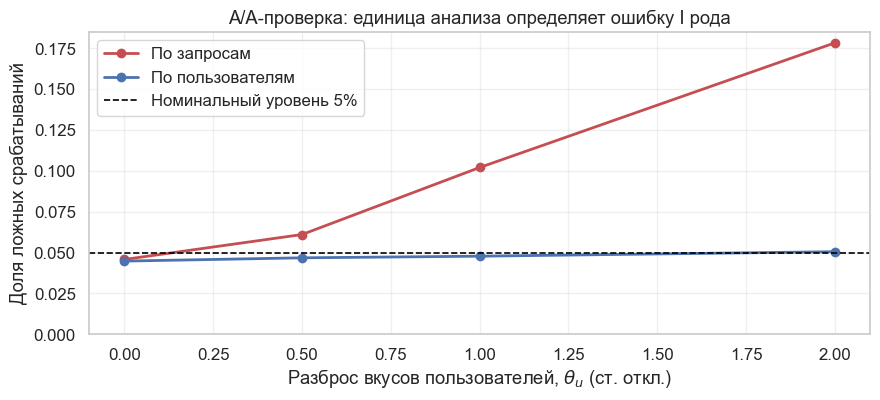

,По запросам,По пользователям
0.0,0.046,0.045
0.5,0.061,0.047
1.0,0.102,0.048
2.0,0.178,0.050


In [10]:
def fpr_by_unit(data: pd.DataFrame, n_users: int = 2000, n_sims: int = 4000, seed: int = 0) -> dict:
    """Считает FPR критерия знаков по запросам и по пользователям при верной H0."""
    rng = np.random.default_rng(seed)
    wins_a, wins_b = data['wins_a'].to_numpy(), data['wins_b'].to_numpy()
    rejected = np.zeros(2)
    z_crit = stats.norm.ppf(1 - ALPHA / 2)
    for _ in range(n_sims):
        idx = rng.integers(len(data), size=n_users)
        swap = rng.random(n_users) < 0.5
        first, second = np.where(swap, wins_b[idx], wins_a[idx]), np.where(swap, wins_a[idx], wins_b[idx])
        by_query = abs(second.sum() - first.sum()) / np.sqrt(first.sum() + second.sum())
        prefer_second, prefer_first = (second > first).sum(), (second < first).sum()
        by_user = abs(prefer_second - prefer_first) / np.sqrt(prefer_second + prefer_first)
        rejected += [by_query > z_crit, by_user > z_crit]
    return dict(zip(['По запросам', 'По пользователям'], rejected / n_sims))


taste_levels = [0.0, 0.5, 1.0, 2.0]
fpr_table = pd.DataFrame({taste: fpr_by_unit(simulate_pool(150_000, taste_sd=taste, tilt=0.6, mean_queries=6, seed=10)) for taste in taste_levels}).T

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(fpr_table.index, fpr_table['По запросам'], color=RED, marker='o', linewidth=2, label='По запросам')
ax.plot(fpr_table.index, fpr_table['По пользователям'], color=BLUE, marker='o', linewidth=2, label='По пользователям')
ax.axhline(ALPHA, color='black', linestyle='--', linewidth=1.2, label='Номинальный уровень 5%')
ax.set(xlabel='Разброс вкусов пользователей, $\\theta_u$ (ст. откл.)', ylabel='Доля ложных срабатываний', title='A/A-проверка: единица анализа определяет ошибку I рода', ylim=(0, None))
ax.legend()
plt.tight_layout()
plt.show()
fpr_table.round(3)

Когда вкусы одинаковы, оба подхода держат уровень 5%. С ростом разброса вкусов тест по запросам быстро разваливается: при разбросе 1 он даёт 10% ложных срабатываний, а при разбросе 2 уже 18% вместо 5%. Тест по пользователям остаётся на номинальном уровне при любом разбросе.

Механизм тот же, что в 2.02: зависимые наблюдения занижают оценку дисперсии. Здесь мы специально усилили эффект, взяв шесть запросов на человека и заметное различие в стиле ранжировщиков, но направление вывода от этого не меняется. **Единица анализа должна быть той, на уровне которой наблюдения независимы.** Обычно это пользователь.

## Насколько interleaving чувствительнее A/B-теста

Сравним два дизайна на одном и том же пуле, где B истинно лучше A. Как и в работе Chapelle et al., оцениваем мощность ресэмплированием: многократно берём $N$ пользователей и смотрим, в какой доле случаев тест даёт значимый результат. Заодно сверим результат с формулами.

* **A/B-тест:** половина из $N$ получает A, половина B, сравниваем клики на пользователя тестом Уэлча (при таких выборках он совпадает с z-тестом).
* **Interleaving:** все $N$ пользователей видят смешанную выдачу, применяем критерий знаков по пользователям.

Парный дизайн даёт и формулу. Пусть $s_i \in \{-1, 0, 1\}$ показывает предпочтение пользователя. Тогда

$$N_{IL} \approx \frac{(z_{1-\alpha/2} + z_{1-\beta})^2\,\text{Var}(s)}{(\mathbb{E}\,s)^2}.$$

Сравните с $N_{AB}$: в знаменателе вместо малого эффекта на уровень метрики стоит средний сдвиг предпочтения, а в числителе вместо разброса кликов стоит ограниченная величина, дисперсия которой не больше 1.

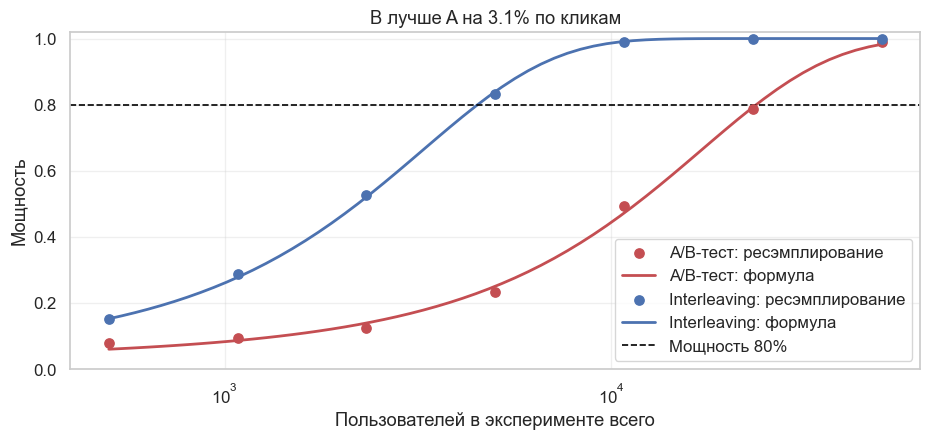

,Пользователей для мощности 80%
A/B,23721.1
Interleaving,4511.8
Выигрыш,5.3


In [11]:
def required_users(data: pd.DataFrame, power: float = 0.8) -> dict:
    """Считает по формулам размер выборки для A/B-теста и для interleaving."""
    z = stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(power)
    variance = (data['clicks_a'].var() + data['clicks_b'].var()) / 2
    delta = data['clicks_b'].mean() - data['clicks_a'].mean()
    preference = np.sign(data['wins_b'] - data['wins_a'])
    n_ab, n_il = 4 * z ** 2 * variance / delta ** 2, z ** 2 * preference.var() / preference.mean() ** 2
    return {'A/B': n_ab, 'Interleaving': n_il, 'Выигрыш': n_ab / n_il}


def power_curves(data: pd.DataFrame, sizes: np.ndarray, n_sims: int = 300, seed: int = 0) -> pd.DataFrame:
    """Оценивает мощность обоих дизайнов ресэмплированием."""
    rng = np.random.default_rng(seed)
    clicks_a, clicks_b = data['clicks_a'].to_numpy(), data['clicks_b'].to_numpy()
    preference = np.sign(data['wins_b'] - data['wins_a']).to_numpy()
    share_b, share_a = (preference > 0).mean(), (preference < 0).mean()
    z_crit = stats.norm.ppf(1 - ALPHA / 2)
    rows = []
    for size in sizes:
        hits_ab = 0
        for _ in range(n_sims):
            group_a = clicks_a[rng.integers(len(data), size=size // 2)]
            group_b = clicks_b[rng.integers(len(data), size=size // 2)]
            standard_error = np.sqrt(group_a.var(ddof=1) / len(group_a) + group_b.var(ddof=1) / len(group_b))
            hits_ab += abs(group_b.mean() - group_a.mean()) / standard_error > z_crit
        counts = rng.multinomial(size, [share_b, share_a, 1 - share_b - share_a], size=5000)
        z_scores = (counts[:, 0] - counts[:, 1]) / np.sqrt(counts[:, 0] + counts[:, 1])
        rows.append({'N': size, 'A/B': hits_ab / n_sims, 'Interleaving': (np.abs(z_scores) > z_crit).mean()})
    return pd.DataFrame(rows).set_index('N')


sizes = np.logspace(2.7, 4.7, 7).astype(int)
curves = power_curves(pool, sizes)
needed = required_users(pool)

fig, ax = plt.subplots(figsize=(9.5, 4.6))
grid = np.logspace(2.7, 4.7, 60)
z_crit = stats.norm.ppf(1 - ALPHA / 2)
for label, column, color in [('A/B-тест', 'A/B', RED), ('Interleaving', 'Interleaving', BLUE)]:
    ax.scatter(curves.index, curves[column], color=color, s=45, zorder=3, label=f'{label}: ресэмплирование')
    theory = stats.norm.cdf(np.sqrt(grid / needed[column]) * (z_crit + stats.norm.ppf(0.8)) - z_crit)
    ax.plot(grid, theory, color=color, linewidth=2, label=f'{label}: формула')
ax.axhline(0.8, color='black', linestyle='--', linewidth=1.2, label='Мощность 80%')
ax.set(xscale='log', xlabel='Пользователей в эксперименте всего', ylabel='Мощность', title=f"B лучше A на {lift:.1%} по кликам", ylim=(0, 1.02))
ax.legend()
plt.tight_layout()
plt.show()
pd.Series(needed).round(1).to_frame('Пользователей для мощности 80%')

Для мощности 80% interleaving хватает примерно 4.5 тысячи пользователей, а A/B-тесту нужно около 23.7 тысячи. Выигрыш в 5.3 раза. Точки ресэмплирования легли на кривые формул, так что формулам можно доверять.

Выигрыш зависит от устройства продукта. Посмотрим, как он меняется вместе с разбросом активности пользователей и с размером различия ранжировщиков.

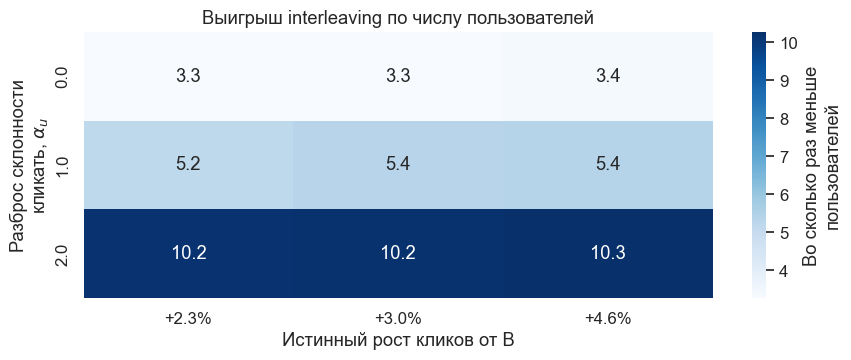

In [12]:
click_levels, sigma_levels = [0.0, 1.0, 2.0], [0.85, 0.8, 0.7]
gain_grid = pd.DataFrame(index=click_levels, columns=sigma_levels, dtype=float)
needed_by_sigma, lift_by_sigma = {}, {}
for click_sd in click_levels:
    for sigma in sigma_levels:
        runs = [simulate_pool(150_000, sigma_b=sigma, click_sd=click_sd, seed=seed) for seed in range(3)]
        estimates = pd.DataFrame([required_users(data) for data in runs]).mean()
        gain_grid.loc[click_sd, sigma] = estimates['Выигрыш']
        if click_sd == 1.0:
            needed_by_sigma[sigma] = estimates
            lift_by_sigma[sigma] = np.mean([data['clicks_b'].mean() / data['clicks_a'].mean() - 1 for data in runs])

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.heatmap(gain_grid, annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': 'Во сколько раз меньше\nпользователей'}, ax=ax,
            xticklabels=[f'{lift_by_sigma[sigma]:+.1%}' for sigma in sigma_levels], yticklabels=click_levels)
ax.set(xlabel='Истинный рост кликов от B', ylabel='Разброс склонности\nкликать, $\\alpha_u$', title='Выигрыш interleaving по числу пользователей')
plt.tight_layout()
plt.show()

Каждая клетка усреднена по трём прогонам: на одном прогоне оценка заметно шумит, особенно при малом эффекте, потому что и $\delta$, и $\mathbb{E}\,s$ стоят в знаменателе в квадрате. Здесь два вывода, и второй не вполне интуитивный.

1. **Выигрыш определяется разбросом пользователей.** Он растёт от 3.3 раза, когда склонность кликать у всех одинакова, до 10 раз при большом разбросе. Это ровно то, что мы и обещали: парный дизайн убирает разницу между людьми, поэтому чем она больше, тем больше выигрыш.
2. **Выигрыш почти не зависит от размера эффекта.** Обе выборки растут как единица на квадрат эффекта, поэтому их отношение остаётся примерно постоянным. Значит, неверно говорить, что interleaving особенно хорош именно на маленьких эффектах. Просто при маленьком эффекте A/B требует недостижимого трафика, а interleaving ещё укладывается в доступный.

Даже без разброса выигрыш больше единицы: остаются случайность кликов и разница в активности, а также то, что interleaving использует весь трафик, а не делит его пополам.

Покрутите качество ранжировщика B и посмотрите, как меняется необходимый трафик.

In [13]:
def power_demo(sigma_b: float = 0.8) -> None:
    """Рисует теоретические кривые мощности при выбранном качестве ранжировщика B."""
    needed_now = needed_by_sigma[sigma_b]
    grid = np.logspace(3, 6.2, 80)
    z_crit = stats.norm.ppf(1 - ALPHA / 2)
    fig, ax = plt.subplots(figsize=(9.5, 4.2))
    for label, color in [('A/B', RED), ('Interleaving', BLUE)]:
        power_values = stats.norm.cdf(np.sqrt(grid / needed_now[label]) * (z_crit + stats.norm.ppf(0.8)) - z_crit)
        ax.plot(grid, power_values, color=color, linewidth=2, label=f'{label}: {needed_now[label]:,.0f} на мощность 80%'.replace(',', ' '))
    ax.axhline(0.8, color='black', linestyle='--', linewidth=1.2)
    ax.set(xscale='log', xlabel='Пользователей всего', ylabel='Мощность', ylim=(0, 1.02), title=f"Рост кликов {lift_by_sigma[sigma_b]:+.1%}, выигрыш в {needed_now['Выигрыш']:.1f} раза")
    ax.legend(loc='upper left')
    plt.tight_layout()
    plt.show()


interact(power_demo, sigma_b=SelectionSlider(options=sigma_levels, value=0.8, description='σ B'));

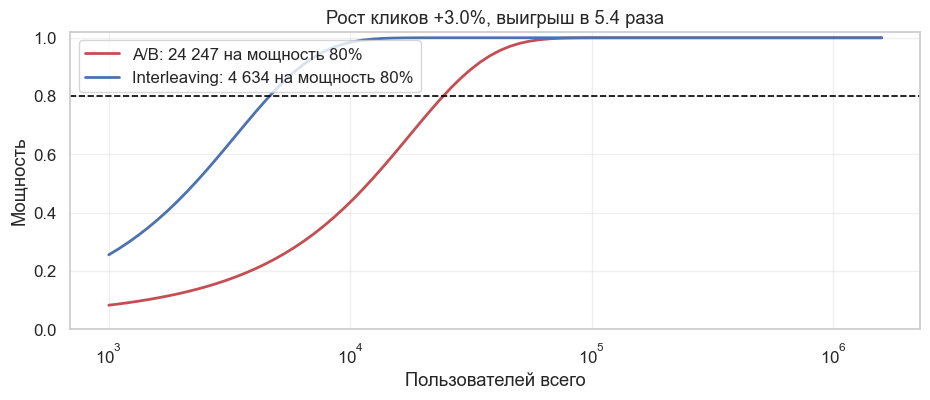

In [14]:
power_demo(0.8)

Что сообщается в литературе:

| Источник | Что сравнивали | Результат |
|---|---|---|
| Chapelle et al., 2012 | Balanced Interleaving и метрика Clicks@1 в поиске | Данных меньше более чем на порядок; из всех пар в одной interleaving оказался менее чувствительным |
| Bi et al., 2022 (Amazon) | Debiased Balanced и A/B, 10 онлайн-экспериментов | Оценочно 60x |
| Zhang et al., 2025 (Airbnb) | Competitive pairs и A/B, конверсия | Около 50x |
| Bi et al., 2023 (Amazon) | Обзор опубликованных работ | 10–100x |

Наши 5 раз заметно скромнее, и это не противоречие. Выигрыш зависит от метрики, разброса пользователей и степени различия выдач, а опубликованные оценки получены на других продуктах: у Airbnb, например, целевое событие редкое (бронирование), а competitive pairs специально снижают шум на редких событиях. **Цифры вроде «в 50 раз» нельзя переносить на свой продукт.** Выигрыш надо измерять на своих парных экспериментах.

## Как проверить, что interleaving работает

Interleaving — это новая инфраструктура и новые ошибки: неудачная монетка, неверная атрибуция клика, разные таймауты у двух моделей. Поэтому метод проверяют так же строго, как и обычный A/B (см. A/A-проверку в 2.02). Ниже набор проверок из практики Airbnb, Amazon и Авито.

**1. A/A-тест.** Сравниваем ранжировщики, равные по качеству. Здесь есть ловушка: если взять **один и тот же** ранжировщик дважды, то при competitive pairs не будет ни одной соревнующейся пары, и тест ничего не проверит. При Team Draft идентичные выдачи проверят только монетку и атрибуцию. Осмысленная проверка берёт разные, но равные по качеству модели.

**2. Случайные клики.** Проверка из статьи Amazon: при кликах, не зависящих от документа, значимой разницы быть не должно, даже если один ранжировщик объективно лучше.

**3. Контроль качества данных.** Airbnb проверяет каждый эксперимент как обычный тест на нейтральных метриках: команды должны получать равное число показов, и каждая должна идти первой в паре в 50% случаев. Если проверка не проходит, эксперимент считается невалидным.

Проверим всё это и заодно сломаем монетку: пусть из-за ошибки A выбирает первым в 55% случаев вместо 50%.

Соревнующихся пар при одинаковых выдачах: 0


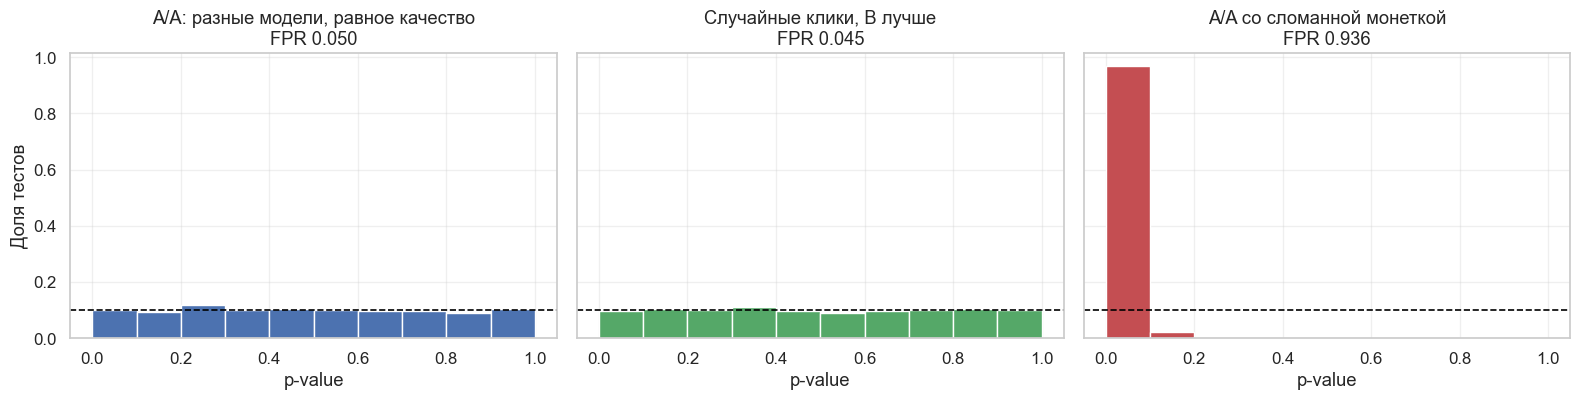

,FPR,Доля A на первой позиции,p-value проверки монетки
Сценарий,,,
"A/A: разные модели, равное качество",0.050,0.5000,0.9810
"Случайные клики, B лучше",0.045,0.4996,0.6101
A/A со сломанной монеткой,0.936,0.5503,0.0000


In [15]:
print('Соревнующихся пар при одинаковых выдачах:', len(competitive_pairs(list('abcdef'), list('abcdef'), True)[1]))


def sign_test_pvalues(data: pd.DataFrame, n_users: int = 5000, n_sims: int = 2000, seed: int = 0) -> np.ndarray:
    """Считает p-value критерия знаков по пользователям на подвыборках."""
    rng = np.random.default_rng(seed)
    preference = np.sign(data['wins_b'] - data['wins_a']).to_numpy()
    p_values = np.empty(n_sims)
    for sim in range(n_sims):
        sample = preference[rng.integers(len(data), size=n_users)]
        wins, losses = (sample > 0).sum(), (sample < 0).sum()
        p_values[sim] = 2 * stats.norm.sf(abs(wins - losses) / np.sqrt(wins + losses))
    return p_values


scenarios = {
    'A/A: разные модели, равное качество': simulate_pool(150_000, seed=41),
    'Случайные клики, B лучше': simulate_pool(150_000, sigma_b=0.8, random_clicks=True, seed=42),
    'A/A со сломанной монеткой': simulate_pool(150_000, p_a_first=0.55, seed=43),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
rows = []
for ax, (name, data), color in zip(axes, scenarios.items(), [BLUE, GREEN, RED]):
    p_values = sign_test_pvalues(data)
    ax.hist(p_values, bins=np.linspace(0, 1, 11), color=color, weights=np.full(len(p_values), 1 / len(p_values)), edgecolor='white')
    ax.axhline(0.1, color='black', linestyle='--', linewidth=1.2)
    ax.set(xlabel='p-value', title=f'{name}\nFPR {(p_values <= ALPHA).mean():.3f}')
    queries = data['n_queries'].sum()
    first_share = data['first_a'].sum() / queries
    check = stats.binomtest(int(data['first_a'].sum()), int(queries), 0.5).pvalue
    rows.append({'Сценарий': name, 'FPR': (p_values <= ALPHA).mean(), 'Доля A на первой позиции': first_share, 'p-value проверки монетки': check})
axes[0].set_ylabel('Доля тестов')
plt.tight_layout()
plt.show()
pd.DataFrame(rows).set_index('Сценарий').round(4)

A/A на разных, но равных по качеству моделях даёт равномерные p-value и FPR 5.0%, случайные клики дают 4.5%. Обе проверки пройдены. Competitive pairs на одинаковых выдачах действительно не дают ни одной пары.

Сломанная монетка показывает, зачем нужен контроль качества. Перекос всего на 5 процентных пунктов приводит к тому, что A/A-тест ложно находит разницу в 94% случаев: A чаще стоит выше и из-за позиционного смещения собирает больше кликов. При этом результат выглядел бы как надёжный вывод. Проверка монетки ловит такую поломку сразу: доля A на первой позиции равна 55.0%, p-value практически нулевой. А вот проверка на равенство показов её бы не поймала: Team Draft по построению даёт командам поровну документов, а портится только их порядок. Поэтому Airbnb смотрит на обе метрики.

**4. Парные эксперименты.** Самая содержательная проверка: для части кандидатов запускаем и interleaving, и обычный A/B, а затем сравниваем знаки эффектов. Amazon называет такие A/B-тесты сопутствующими (companion) и рекомендует постоянно следить за этой статистикой как за здоровьем системы.

Несовпадение знака само по себе не значит, что метод сломан: при малом эффекте оба измерения шумные. Если оценка распределена как $\mathcal{N}(\mu, s^2)$, то вероятность ошибиться в знаке равна $p = \Phi(-|\mu|/s)$. Несовпадение возникает, когда ошибся ровно один из двух экспериментов:

$$P(\text{знаки разошлись}) = p_{AB} + p_{IL} - 2\,p_{AB}\,p_{IL}.$$

В статье Amazon (Bi et al., 2023) слова те же, «ровно один», но в формуле стоит $p_{AB} + p_{IL} - p_{AB}\,p_{IL}$. Это вероятность события «хотя бы один». При малых вероятностях разница мала, но мы используем точную форму.

Смоделируем 120 пар экспериментов со случайным качеством B. На interleaving отдаём 10% трафика, на A/B остальные 90%.

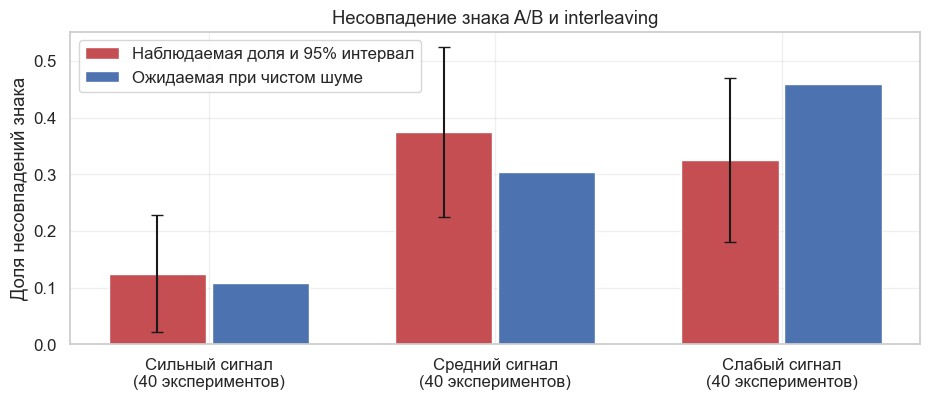

Несовпадений знака: 27.5%, ожидается из-за шума: 29.1%


,experiments,observed,expected
p_disagree,,,
Сильный сигнал,40,0.125,0.108
Средний сигнал,40,0.375,0.305
Слабый сигнал,40,0.325,0.460


In [16]:
def companion_experiments(n_experiments: int = 120, n_users: int = 20_000, seed: int = 50) -> pd.DataFrame:
    """Запускает пары interleaving и A/B на непересекающихся пользователях."""
    rng = np.random.default_rng(seed)
    rows = []
    n_il = n_users // 10
    for experiment in range(n_experiments):
        sigma = rng.uniform(0.8, 1.2)
        data = simulate_pool(n_users, sigma_b=sigma, seed=1000 + experiment)
        il, ab = data.iloc[:n_il], data.iloc[n_il:]
        preference = np.sign(il['wins_b'] - il['wins_a'])[il['clicks_merged'] > 0]
        half = len(ab) // 2
        group_a, group_b = ab['clicks_a'].iloc[:half], ab['clicks_b'].iloc[half:]
        rows.append({
            'sigma_b': sigma,
            'il': preference.mean() / 2,
            'il_se': preference.std() / 2 / np.sqrt(len(preference)),
            'ab': group_b.mean() - group_a.mean(),
            'ab_se': np.sqrt(group_a.var() / len(group_a) + group_b.var() / len(group_b)),
        })
    return pd.DataFrame(rows)


companion = companion_experiments()
p_ab = stats.norm.cdf(-companion['ab'].abs() / companion['ab_se'])
p_il = stats.norm.cdf(-companion['il'].abs() / companion['il_se'])
companion['p_disagree'] = p_ab + p_il - 2 * p_ab * p_il
companion['disagree'] = np.sign(companion['ab']) != np.sign(companion['il'])
groups = pd.qcut(companion['p_disagree'], 3, labels=['Сильный сигнал', 'Средний сигнал', 'Слабый сигнал'])
calibration = companion.groupby(groups, observed=True).agg(experiments=('disagree', 'size'), observed=('disagree', 'mean'), expected=('p_disagree', 'mean'))
error = 1.96 * np.sqrt(calibration['observed'] * (1 - calibration['observed']) / calibration['experiments'])

fig, ax = plt.subplots(figsize=(9.5, 4.2))
positions = np.arange(len(calibration))
ax.bar(positions - 0.18, calibration['observed'], width=0.34, color=RED, yerr=error, capsize=4, label='Наблюдаемая доля и 95% интервал')
ax.bar(positions + 0.18, calibration['expected'], width=0.34, color=BLUE, label='Ожидаемая при чистом шуме')
ax.set_xticks(positions, [f'{name}\n({count} экспериментов)' for name, count in zip(calibration.index, calibration['experiments'])])
ax.set(ylabel='Доля несовпадений знака', title='Несовпадение знака A/B и interleaving', ylim=(0, None))
ax.legend()
plt.tight_layout()
plt.show()
print(f"Несовпадений знака: {companion['disagree'].mean():.1%}, ожидается из-за шума: {companion['p_disagree'].mean():.1%}")
calibration.round(3)

Несовпадений 27.5% при ожидании 29.1%. Ожидаемые значения попадают в интервалы наблюдаемых, систематического превышения нет. Интервалы широкие, по 40 экспериментов на группу: при другом зерне наблюдаемая доля заметно меняется. В группе со слабым сигналом ожидание выше наблюдаемого: формула подставляет оценки вместо истинных значений, а при шумной оценке близкой к нулю даёт $p$ около 0.5. На слабом сигнале это скорее верхняя прикидка.

Важно, что в нашей модели нет никаких систематических расхождений: оба метода измеряют одно и то же качество. И всё же знаки расходятся больше чем в четверти экспериментов, потому что interleaving получил лишь 10% трафика, а эффекты малы. У Airbnb совпадение по 29 парам составило 82%, то есть расхождение 18%. Сравнивать это с нашей цифрой напрямую нельзя, но пример показывает, что такой уровень сам по себе ещё не означает поломку. Тревожным сигналом было бы превышение над ожидаемым из-за шума. Amazon на 75 парах такого превышения не обнаружил.

**5. Транзитивность.** Если A лучше B, а B лучше C, то A должен быть лучше C. Amazon строит ориентированный граф значимых парных сравнений: цикл в нём означает нарушение. На их данных при групповой ошибке 0.1 нарушений не нашлось.

**6. Офлайн-приёмка.** Авито перед запуском прогоняет метод на симуляции выдачи по реальному пулу запросов. Об этом подробнее в разделе про кейсы.

## Ограничения

**Предпочтение не равно бизнес-эффекту.** $\Delta$ показывает направление, но не величину в единицах метрики. Amazon предлагает переводить результат в шкалу A/B с помощью взвешенной регрессии через ноль по накопленным парам экспериментов:

$$ATE_{AB} = \beta \cdot ATE_{IL} + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, \sigma^2 / w).$$

Свободного члена нет: без эффекта оба измерения дают ноль, а смена имён ранжировщиков меняет знак обоих. По 75 парам экспериментов Amazon получил отчётливую линейную связь. Проверим подход на наших парах.

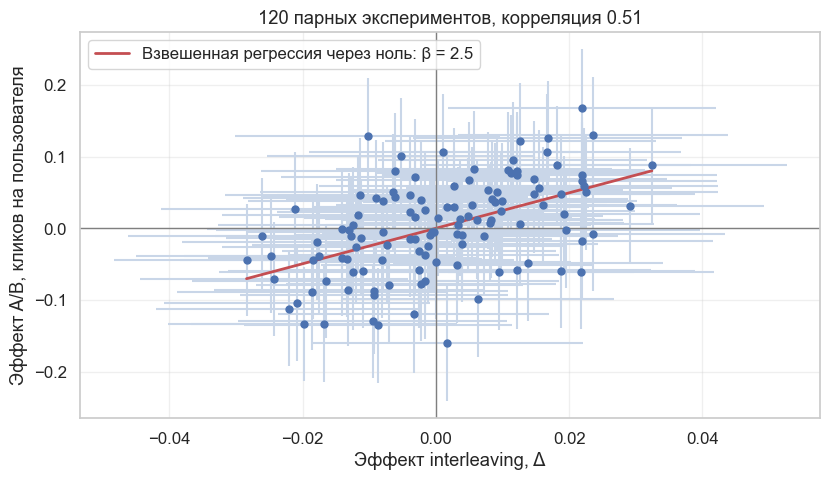

In [17]:
weights = 1 / companion['ab_se'] ** 2
beta = (weights * companion['il'] * companion['ab']).sum() / (weights * companion['il'] ** 2).sum()
correlation = np.corrcoef(companion['il'], companion['ab'])[0, 1]

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.errorbar(companion['il'], companion['ab'], xerr=1.96 * companion['il_se'], yerr=1.96 * companion['ab_se'], fmt='o', color=BLUE, ecolor='#C9D6E8', markersize=5, zorder=2)
line = np.array([companion['il'].min(), companion['il'].max()])
ax.plot(line, beta * line, color=RED, linewidth=2, label=f'Взвешенная регрессия через ноль: β = {beta:.1f}')
ax.axhline(0, color=GRAY, linewidth=1)
ax.axvline(0, color=GRAY, linewidth=1)
ax.set(xlabel='Эффект interleaving, Δ', ylabel='Эффект A/B, кликов на пользователя', title=f'{len(companion)} парных экспериментов, корреляция {correlation:.2f}')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

Связь линейна, $\beta = 2.5$: сдвиг $\Delta$ на один процентный пункт соответствует примерно 0.025 клика на пользователя. Коэффициент специфичен для продукта и метрики, поэтому его оценивают на своих парах и обновляют, а не берут из чужой статьи.

Корреляция здесь равна всего 0.51, хотя в модели оба метода меряют одно и то же. Весь недостаток до единицы даёт шум измерений. Отсюда правило чтения таких цифр: корреляция 0.6 у Airbnb сама по себе не говорит о том, насколько методы расходятся по существу. Часть расхождений обязана шуму, а часть, как мы увидим дальше, настоящая.

**Эффекты на уровне всей выдачи.** Interleaving оценивает отдельные документы в смешанном списке, а пользователь в A/B видит выдачу целиком. Airbnb описывает такой случай: ранжировщик улучшал второстепенную цель и должен был оставить конверсию нейтральной. A/B так и показал, а interleaving дал значимо отрицательный результат: рядом с контрольными объектами тестовые выглядели хуже.

Покажем механизм на чистом примере. Есть два интереса: основной у 70% пользователей и нишевый у 30%. Ранжировщик A показывает только основные документы, ранжировщик B чередует основные и нишевые. Успех сессии означает хотя бы один клик.

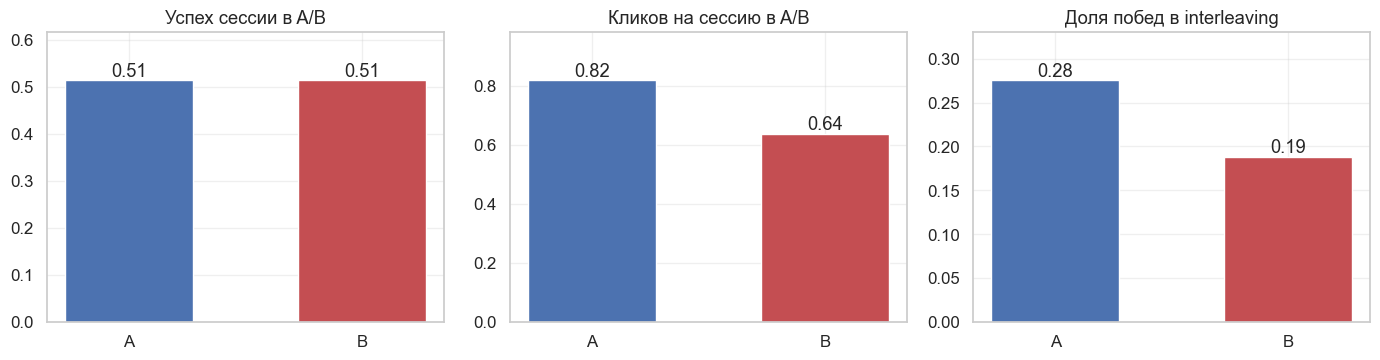

,A: однородная,B: разнообразная
Успех сессии в A/B,0.513,0.514
Кликов на сессию в A/B,0.818,0.636
Доля побед в interleaving,0.275,0.188


In [18]:
def diversity_experiment(n_users: int = 300_000, share_main: float = 0.7, liking: float = 0.4, seed: int = 60) -> dict:
    """Сравнивает однородную и разнообразную выдачи в A/B и в interleaving."""
    rng = np.random.default_rng(seed)
    main_docs, niche_docs = np.arange(10), np.arange(10, 20)
    homogeneous = np.concatenate([main_docs, niche_docs])
    diverse = np.ravel(np.column_stack([main_docs, niche_docs]))
    A, B = np.tile(homogeneous, (n_users, 1)), np.tile(diverse, (n_users, 1))
    likes_main = rng.random(n_users) < share_main
    attraction = np.where(np.arange(POOL) < 10, likes_main[:, None], ~likes_main[:, None]) * liking
    rows = np.arange(n_users)[:, None]

    def show(order: np.ndarray) -> np.ndarray:
        return rng.random((n_users, K)) < EXAMINATION * attraction[rows, order[:, :K]]

    clicks_a, clicks_b = show(A), show(B)
    merged, from_b = team_draft_batch(A, B, rng)
    clicks = show(merged)
    credit_a, credit_b = (clicks & ~from_b).sum(axis=1), (clicks & from_b).sum(axis=1)
    return {
        'Успех сессии в A/B': (clicks_a.any(axis=1).mean(), clicks_b.any(axis=1).mean()),
        'Кликов на сессию в A/B': (clicks_a.sum(axis=1).mean(), clicks_b.sum(axis=1).mean()),
        'Доля побед в interleaving': ((credit_a > credit_b).mean(), (credit_b > credit_a).mean()),
    }


diversity = pd.DataFrame(diversity_experiment(), index=['A: однородная', 'B: разнообразная']).T

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (name, values) in zip(axes, diversity.iterrows()):
    ax.bar(['A', 'B'], values.values, color=[BLUE, RED], width=0.55)
    ax.set(title=name, ylim=(0, max(values) * 1.2))
    for position, value in enumerate(values.values):
        ax.text(position, value, f'{value:.2f}', ha='center', va='bottom')
plt.tight_layout()
plt.show()
diversity.round(3)

Картина похожа на случай Airbnb. По успеху сессии A/B-тест нейтрален: 0.513 против 0.514. Interleaving уверенно выбирает A: 27.5% побед против 18.8% (остальное составляют ничьи и запросы без кликов).

Никто здесь не ошибся, методы отвечают на разные вопросы. В смешанной выдаче документы основного интереса видны всем, и большинство пользователей кликает на них, а они чаще принадлежат команде A. Польза разнообразия проявляется только у выдачи целиком: B покрывает оба интереса и потому не теряет в успехе, хотя отдельные его документы привлекают меньше. Заметьте: по числу кликов A/B согласился бы с interleaving (0.82 против 0.64). Расхождение появляется только на метрике всей выдачи.

**Вывод:** если изменение меняет свойства списка целиком (разнообразие, свежесть, учёт второстепенной цели), interleaving может дать ложную тревогу. Такие кандидаты надо сразу проверять в A/B.

**Слепая зона Team Draft.** Несмещённость не гарантирует, что метод видит любое улучшение. Пусть $A = (1, 2, 3, 4)$, $B = (2, 3, 4, 1)$, и релевантен только документ 3. Ранжировщик B объективно лучше: у него нужный документ на второй позиции, а у A на третьей. Переберём все монетки.

In [19]:
def team_draft_outcome(A: list, B: list, relevant: str) -> pd.Series:
    """Перебирает монетки Team Draft и считает победы при клике на единственный релевантный документ."""
    outcomes = []
    for coins in itertools.product('AB', repeat=6):
        merged, team_a, _ = team_draft(A, B, coins)
        outcomes.append({'Позиция документа': merged.index(relevant) + 1, 'Победитель': 'A' if relevant in team_a else 'B'})
    return pd.DataFrame(outcomes).value_counts(normalize=True).rename('Доля исходов')


team_draft_outcome(list('1234'), list('2341'), '3').to_frame().round(3)

Доля исходов
Позиция документа Победитель              
3                 A                    0.5
                  B                    0.5

Документ 3 всегда оказывается на третьей позиции, и команда у него определяется монеткой. Победитель случаен, а B лучше. Это не смещение, а потеря сигнала: ничья не склоняет вывод ни в чью сторону, просто улучшение не видно. Hofmann et al. (2013) считают это нарушением свойства fidelity, то есть соответствия интуиции о том, что ранжировщик, поставивший нужный документ выше, должен выигрывать. Amazon показывает похожую слабость Team Draft на симуляциях.

С этим есть и контраргумент. Airbnb разбирает ровно такой пример и утверждает, что на практике проблем он не создаёт: их данные по контрфактической оценке показывают, что сдвиг на одну позицию разумно считать ничьей, и что на чувствительность это не влияет.

**Остальные ограничения.**

* **Только ранжирование.** Новый продукт, дизайн или цену так не протестировать: сравниваются списки объектов.
* **Непрерывные метрики.** Airbnb отмечает, что для выручки трудно определить осмысленную метрику. Amazon при этом использует вещественный кредит, например за покупки, так что вопрос решается в зависимости от задачи.
* **Другие поверхности.** Если список используется ещё где-то, как карта у Airbnb, смешивание может нарушить опыт пользователя.
* **Долгосрочные эффекты.** Предпочтение измеряется в момент выбора, поэтому удержание и привыкание остаются за A/B-тестом.
* **Инфраструктура.** На каждый запрос надо получить результаты от обоих ранжировщиков, смешать их и залогировать команды. Разные задержки моделей тоже надо учитывать.
* **Два ранжировщика.** Сравнение попарное. Amazon сравнил 10 ранжировщиков всеми 45 парами с поправкой Бонферрони $\alpha = 0.1/45$ (см. 1.03) и упорядочил их через транзитивность. По их оценке, в A/B это заняло бы более чем втрое больше времени и в 2.5 раза больше трафика.

## Развитие метода и кейсы

**Методы.** Кратко о том, что появилось после Team Draft:

* **Probabilistic Interleaving** (Hofmann et al., 2011). Документы выбираются случайно с вероятностью, убывающей с рангом, а кредит считается с учётом всех способов получить такую выдачу. Метод устраняет проблему fidelity, но обходится дорого в вычислениях и иногда поднимает плохие документы наверх, портя выдачу.
* **Generalized Team Draft** (Kharitonov et al., 2015, Яндекс и Университет Глазго). Совместно оптимизирует на данных функцию кредита и политику показа, плюс стратифицирует оценку. В медиане требует в 4.2 раза меньше взаимодействий, чем Team Draft с линейным скорингом без стратификации. Метод работает и для сеток, например в поиске по картинкам.
* **Debiased Balanced Interleaving** (Bi et al., 2022, Amazon). Сохраняет простое смешивание Balanced и исправляет кредит так, что смещение от пересечения выдач исчезает.
* **Multileaving** (Schuth et al., 2014). Смешивание сразу более чем двух ранжировщиков. Amazon отмечает, что в больших экспериментах это трудно реализовать.

**Контрфактическая оценка** (Airbnb). Это не interleaving. Пользователь видит обычную выдачу A или B, а вторая выдача считается параллельно, но не показывается. Сравнивая показанный результат с несостоявшимся, можно получить более чувствительные метрики без смешивания. Это снимает часть ограничений interleaving: карта не ломается, а опыт пользователя остаётся обычным. Airbnb сообщает о выигрыше до 100 раз в зависимости от подхода и метрики.

**Где применяют.**

| Компания | Что делают | Результат |
|---|---|---|
| Airbnb | Competitive pairs в поиске как основная оценка перед A/B | Около 50x; 82% совпадения знака и корреляция 0.6 по 29 парам |
| Amazon | Debiased Balanced в поиске | 60x; 75 пар с A/B и перевод эффекта в шкалу A/B |
| Netflix | Interleaving для персонализации (Parks et al., 2017) | В блоге заявлена сильная связь с A/B-метриками |
| Авито | Counterfactual interleaving в монетизации | MDE выручки 2.5% вместо 8.5% в кластерном тесте |
| LinkedIn | Counterfactual interleaving в рекомендациях связей | Исправлено смещение прежнего дизайна |

### Counterfactual interleaving: Авито и LinkedIn

Название похожее, но задача другая. Осторожно с терминами: **counterfactual interleaving не то же самое, что контрфактическая оценка Airbnb.** Там выдачи не смешиваются, а здесь смешиваются.

Классический interleaving спрашивает, какой ранжировщик нравится покупателям. Но изменение ранжирования затрагивает и другую сторону: продавцов и авторов. Удержание продавца, которого подняли в выдаче, в A/B по покупателям не видно: как объясняет Авито, в половине показов его объявление идёт как обычно. Если же делить на группы самих продавцов, появляется интерференция: они конкурируют за одни и те же места в выдаче (см. 2.02).

На схеме слева пример Авито. Числа означают выручку с позиции, а раскладку по ячейкам мы восстановили из сумм в статье. Частники в контроле приносят 2.2, а при раскатке на всех 3.0. В A/B по продавцам тестовые частники занимают верхние места и вытесняют контрольных вниз: группы сравниваются не с миром без изменения, а друг с другом.

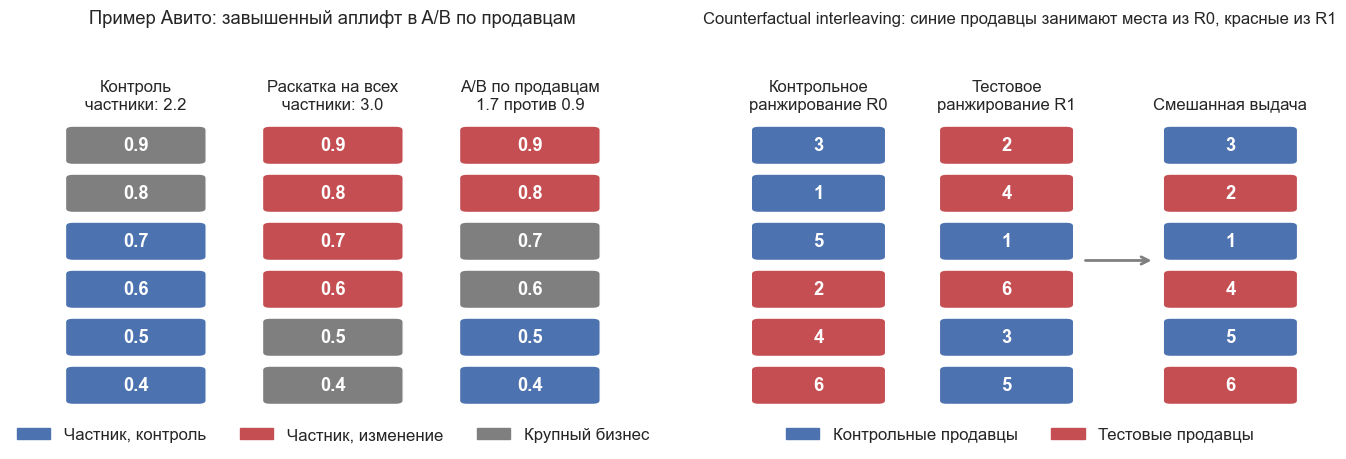

Истинный аплифт: +36%, оценка A/B по продавцам: +89%


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

revenue = [0.9, 0.8, 0.7, 0.6, 0.5, 0.4]
columns = {
    'Контроль': ([GRAY, GRAY, BLUE, BLUE, BLUE, BLUE], 2.2),
    'Раскатка на всех': ([RED, RED, RED, RED, GRAY, GRAY], 3.0),
    'A/B по продавцам': ([RED, RED, GRAY, GRAY, BLUE, BLUE], None),
}
for x, (name, (colors, total)) in zip([0, 2.1, 4.2], columns.items()):
    label = f'{name}\nчастники: {total:.1f}' if total else f'{name}\n1.7 против 0.9'
    draw_ranking(axes[0], x, [f'{value:.1f}' for value in revenue], colors, label)
axes[0].legend(handles=[Patch(color=BLUE, label='Частник, контроль'), Patch(color=RED, label='Частник, изменение'), Patch(color=GRAY, label='Крупный бизнес')], loc='upper center', bbox_to_anchor=(0.5, 0.03), ncol=3, frameon=False)
axes[0].set(xlim=(-0.3, 6), ylim=(-5.4, 2.6))
axes[0].set_title('Пример Авито: завышенный аплифт в A/B по продавцам', pad=12)
axes[0].axis('off')

R0, R1 = ['3', '1', '5', '2', '4', '6'], ['2', '4', '1', '6', '3', '5']
control_sellers = {'1', '3', '5'}
paint = lambda items: [BLUE if item in control_sellers else RED for item in items]
merged_sellers = ['3', '2', '1', '4', '5', '6']
draw_ranking(axes[1], 0, R0, paint(R0), 'Контрольное\nранжирование R0')
draw_ranking(axes[1], 2.1, R1, paint(R1), 'Тестовое\nранжирование R1')
draw_ranking(axes[1], 4.6, merged_sellers, paint(merged_sellers), 'Смешанная выдача')
axes[1].annotate('', xy=(4.5, -2), xytext=(3.7, -2), arrowprops={'arrowstyle': '->', 'color': GRAY, 'lw': 2})
axes[1].legend(handles=[Patch(color=BLUE, label='Контрольные продавцы'), Patch(color=RED, label='Тестовые продавцы')], loc='upper center', bbox_to_anchor=(0.5, 0.03), ncol=2, frameon=False)
axes[1].set(xlim=(-0.3, 6.3), ylim=(-5.4, 2.6))
axes[1].set_title('Counterfactual interleaving: синие продавцы занимают места из R0, красные из R1', pad=12, fontsize=12)
axes[1].axis('off')
plt.tight_layout()
plt.show()

print(f'Истинный аплифт: {3 / 2.2 - 1:+.0%}, оценка A/B по продавцам: {1.7 / 0.9 - 1:+.0%}')

Истинный аплифт равен +36%, а A/B по продавцам покажет +89% (1.7 / 0.9; в статье Авито округлено до 1.88). Тестовые продавцы выигрывают за счёт контрольных, и эффект завышается более чем вдвое.

**Как устроен дизайн** (схема справа):

1. Продавцы заранее делятся на контрольную и тестовую группы.
2. На каждый запрос строятся оба ранжирования: R0 как при контрольной модели для всех и R1 как при тестовой. Это и есть контрфактические выдачи.
3. Контрольный продавец получает своё место из R0, тестовый из R1. Так каждая группа ведёт себя так, будто модель раскатана на всех.
4. Если два продавца претендуют на одно место, спор решает монетка. На схеме это места 1 и 2: продавцы 3 и 2, затем 1 и 4.

Вся тонкость в четвёртом шаге. Монетка должна быть устроена так, чтобы шум от споров был одинаковым у групп, а порядок внутри каждого ранжирования сохранялся. LinkedIn показывает, что простая монетка 50 на 50 здесь не подходит: в их симуляции такой дизайн уверенно выбирал худший ранжировщик. А замена прежнего дизайна UniCoRn в продакшене показала, что примерно 85% авторов стояли не на своих местах, в среднем со сдвигом на 2–3 позиции. Вероятности разрешения споров выводить не будем, они есть в статье Wang и Ba.

**Как Авито проверял метод.** Это хороший образец проверок перед запуском:

* **A/A-тест офлайн:** 3 тысячи запросов, подвыборки по 300, t-тест, 10 тысяч повторений. Интервал для уровня значимости 0.05 составил 0.03–0.04, то есть FPR контролируется с небольшим запасом.
* **Доля продавцов в тесте** от 5 до 95%: интервалы перекрываются, но при сильном дисбалансе шум выше.
* **Шум от споров** одинаков в контроле и тесте на тысяче прогонов.
* **Совпадение с истинным аплифтом** на тысяче запросов офлайн.
* **Онлайн:** параллельные A/B по покупателям и interleaving по продавцам в течение недели, аплифты совпали в пределах доверительных интервалов.

**Результат и ограничения.** MDE выручки снизился с 8.5% в кластерном тесте до 2.5%, то есть в 3.4 раза. Авито перечисляет и минусы: соседние объявления всё равно влияют друг на друга, новые продукты так не проверить, а подходят только аддитивные метрики.

## Заключение

* Interleaving показывает каждому пользователю одну смешанную выдачу и измеряет предпочтение между двумя ранжировщиками. Это парный дизайн, поэтому разница между людьми не попадает в оценку.
* Смешивать надо честно. Наивное смешивание страдает от позиционного смещения, а Balanced от пересечения выдач. Team Draft и competitive pairs этих проблем не имеют.
* Монетка бросается на запрос, но единицей анализа должен быть пользователь: тест по запросам завышает ошибку I рода.
* В нашей модели выигрыш в трафике составил от 3 до 10 раз и определялся разбросом пользователей, а не размером эффекта. В литературе встречаются оценки 10–100x, но на свой продукт их переносить нельзя.
* Interleaving отвечает на вопрос о предпочтении, а не о бизнес-эффекте. Эффекты на уровне всей выдачи он может не только пропустить, но и исказить. Поэтому обычная схема такая: interleaving для отсева, A/B для решения.
* Counterfactual interleaving решает другую задачу: оценивает влияние ранжирования на продавцов без интерференции.

**Чек-лист запуска**

1. Изменение касается только порядка объектов и не меняет свойства списка целиком.
2. Метод смешивания несмещён: Team Draft или его варианты.
3. A/A на разных, но равных по качеству моделях держит уровень значимости.
4. Показы и доля первых мест у команд равны в каждом эксперименте.
5. Единица анализа — пользователь, а размер выборки заранее рассчитан.
6. Накоплены парные эксперименты с A/B, совпадение знака не хуже ожидаемого из-за шума.
7. Финалист проходит обычный A/B-тест.